# SpringFF Geometry + Pairwise NN Training Demo

This notebook generates relaxed geometries with `SpringFF`, computes SpringFF energy labels at those geometries, then trains `NNPotentialFF` to reproduce those energies. The training loop is the fast direct NN energy-label fit, displayed with a tqdm progress bar.


In [11]:
import os
import random
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
root_candidates = []
for base in [CWD, *CWD.parents]:
    root_candidates.extend([base, base / "GeoMatry", base / "geomatry"])
for candidate in root_candidates:
    if (candidate / "geomatry" / "__init__.py").is_file():
        ROOT_DIR = candidate
        break
else:
    raise RuntimeError("Could not find the GeoMatry package root containing geomatry/__init__.py")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

os.environ.setdefault("MPLCONFIGDIR", str(Path("/private/tmp/geomatry-matplotlib-cache")))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import torch
from ase.optimize import BFGS
from tqdm.auto import tqdm

from geomatry.ff.NN import NNPotentialFF
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_ff_param, _random_spring_systems
from geomatry.opt_Energy_approximated.calculator import NNFFCalculator, get_ase_atoms


In [12]:
device = torch.device("cpu")
dtype = torch.float64
seed = 42
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)

systemN = 20
N = 8
N_pairs = 12
max_Za = 1
fixed_atom_indices = [0,1,2]

def min_pair_distance(Ra):
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))

spring_ff = SpringFF(max_Za).to(device=device, dtype=dtype)
k_target, r0_target = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)
spring_ff.reset_parameters(k_target.to(dtype), r0_target.to(dtype))

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
Ras = [Ra.to(device=device, dtype=dtype) for Ra in Ras]
Zas = [Za.to(device=device, dtype=torch.long) for Za in Zas]
graph_builders = [get_given_graph_builder(idx_i, idx_j, device=device) for idx_i, idx_j in zip(idx_is, idx_js)]

print(f"Generated {systemN} spring systems with N={N}, N_pairs={N_pairs}, atom types=1..{max_Za}")
print("sample target k", k_target[1:, 1:].mean().item())
print("sample target r0", r0_target[1:, 1:].mean().item())
print("sample min distances", [min_pair_distance(Ra) for Ra in Ras[:3]])


Generated 20 spring systems with N=8, N_pairs=12, atom types=1..1
sample target k 0.10516032872215408
sample target r0 1.3931288721861443
sample min distances [1.0833276577788484, 0.6183940783151836, 0.8184977138028344]


In [13]:
from ase.constraints import FixAtoms
def relax_geometry(ff, Ra, Za, graph_builder, fmax=1e-3, steps=300):
    atoms = get_ase_atoms(Ra, Za)
    atoms.calc = NNFFCalculator(ff, graph_builder)
    atoms.set_constraint(FixAtoms(indices=fixed_atom_indices))
    optimizer = BFGS(atoms, logfile=None)
    optimizer.run(fmax=fmax, steps=steps)
    return torch.tensor(atoms.get_positions(), dtype=Ra.dtype, device=Ra.device)

Ra_star_list = [
    relax_geometry(spring_ff, Ra, Za, graph_builder)
    for Ra, Za, graph_builder in zip(Ras, Zas, graph_builders)
]

with torch.no_grad():
    target_energies = torch.stack([
        spring_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

print(f"Relaxed {len(Ra_star_list)} geometries")
print(f"Target energy range: {target_energies.min().item():.6f} to {target_energies.max().item():.6f}")


Relaxed 20 geometries
Target energy range: 0.001009 to 0.325672


In [14]:
def predict_system_energy(nn_ff, Ra, Za, graph_builder):
    return nn_ff.get_E(Ra.float(), Za.long(), *graph_builder(get_ase_atoms(Ra, Za)))

def batch_predict(nn_ff):
    return torch.stack([
        predict_system_energy(nn_ff, Ra_star, Za, graph_builder)
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ])

nn_ff = NNPotentialFF(max_Za, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(nn_ff.parameters(), lr=3e-3, weight_decay=1e-6)
loss_history = []

epochs = 20001
print_period = 5000
pbar = tqdm(range(epochs), desc="NN spring training")
for epoch in pbar:
    optimizer.zero_grad()
    y_pred = batch_predict(nn_ff)
    loss = torch.mean((y_pred - target_energies) ** 2)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if epoch % print_period == 0 or epoch == epochs - 1:
        with torch.no_grad():
            errors = batch_predict(nn_ff) - target_energies
            rmse = torch.sqrt(torch.mean(errors ** 2)).item()
            mae = torch.mean(torch.abs(errors)).item()
        pbar.set_postfix(loss=f"{loss.item():.6e}", rmse=f"{rmse:.6f}", mae=f"{mae:.6f}")
        tqdm.write(f"Iteration {epoch}, loss={loss.item():.6e}, rmse={rmse:.6f}, mae={mae:.6f}")

print('training complete')


NN spring training:   0%|          | 0/20001 [00:00<?, ?it/s]

Iteration 0, loss=2.050804e+02, rmse=10.737453, mae=10.735431
Iteration 5000, loss=1.345563e-04, rmse=0.011597, mae=0.009037
Iteration 10000, loss=3.013880e-03, rmse=0.024100, mae=0.023432
Iteration 15000, loss=7.997390e-07, rmse=0.000896, mae=0.000726
Iteration 20000, loss=5.456772e-07, rmse=0.000738, mae=0.000640
training complete


Final NN energy RMSE: 0.000738
Final NN energy MAE: 0.000640


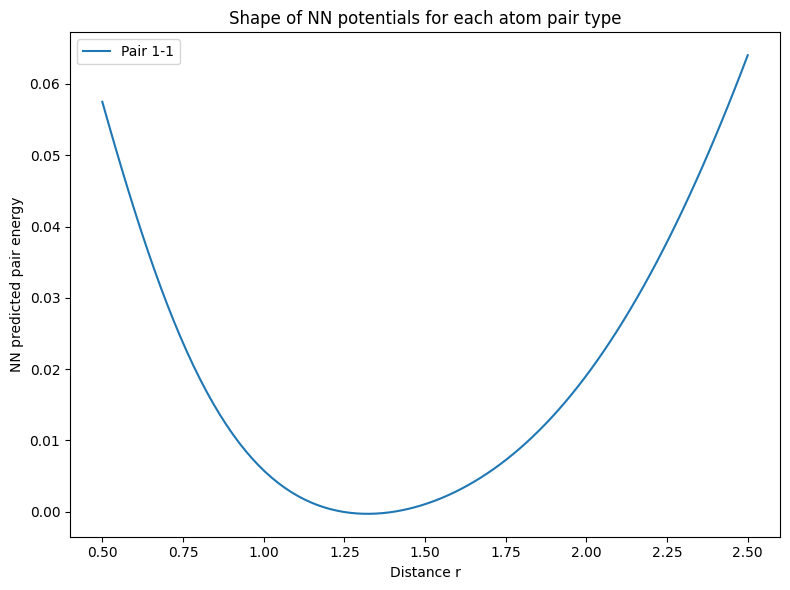

In [17]:
with torch.no_grad():
    energy_errors = batch_predict(nn_ff) - target_energies

rmse = torch.sqrt(torch.mean(energy_errors ** 2)).item()
mae = torch.mean(torch.abs(energy_errors)).item()
print(f"Final NN energy RMSE: {rmse:.6f}")
print(f"Final NN energy MAE: {mae:.6f}")

fig, ax = plt.subplots(figsize=(8, 6))
r_vals = torch.linspace(0.5, 2.5, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        ax.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
ax.set_xlabel('Distance r')
ax.set_ylabel('NN predicted pair energy')
ax.set_title('Shape of NN potentials for each atom pair type')
ax.legend()
plt.tight_layout()
